# Água na Rua — perfis históricos de alagamento

Pergunta: quais distritos de São Paulo apresentam perfis semelhantes de frequência, recorrência e sazonalidade dos registros públicos de alagamento em 2013–2025? Uma linha por distrito; estudo independente do aplicativo, cujo território inicial é o Jardim Peri. Sem rótulos verdadeiros de risco, previsão de enchentes ou avaliação de passagem segura.

As funções legíveis de `ml/estudo.py` implementam cada etapa abaixo. Para avaliação no Google Colab, use a edição de arquivo único `agua_na_rua_colab.ipynb`. Esta edição principal é destinada à leitura no GitHub e à execução local conforme o README.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd() if (Path.cwd()/'ml/estudo.py').exists() else Path.cwd().parent
sys.path.insert(0, str(root/'ml'))
import estudo as e
from IPython.display import display, Markdown, Image
print('Python:', sys.version)
print('Execução:', root.name)

Python: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
Execução: GS-IA-ML


## Fontes e auditoria

Usam-se os GPKGs já fornecidos, com SHA-256 e esquema no manifesto. Fontes oficiais: [ocorrências GeoSampa](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/432c06b1-03a1-4b1f-9210-423e1b58e869) e [Distrito](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/51f75eab-6d90-451e-9f80-c21c1ac72630). Os catálogos foram consultados em 12/11/2026; data e URL direta dos downloads locais não informadas.

Inspecionamos datas e tipos em todos os arquivos, inclusive 2026, antes de filtrar. `data` é a data armazenada na exportação, sem confirmação independente de equivalência ao instante físico do evento. Os nomes previstos na ficha de fontes não correspondem a estas exportações. A cobertura mensal de todos os tipos serve para distinguir mês sem registros de ALAGAMENTO de mês ausente, sem provar exaustividade.

In [2]:
s = e.audit()
display(s['overview'])
display(__import__('pandas').read_csv(e.OUT/'tipos_por_arquivo.csv').pivot(index='ano_arquivo',columns='tipo',values='registros'))
print('Meses observados de todos os tipos:', len(s['coverage']))

C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(


C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(


C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(
C:\Users\User\Desktop\GS-IA-ML\.venv\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original 

,arquivo,ano_arquivo,total,data_min,data_max,datas_invalidas,ano_divergente,meses_todos_tipos,alagamentos,identificadores_vazios,campo_distrito
0,SIRGAS_GPKG_riscoocorrencia_2013.gpkg,2013,2614,2013-01-01,2013-12-31,0,0,12,716,0,False
1,SIRGAS_GPKG_riscoocorrencia_2014.gpkg,2014,2782,2014-01-01,2014-12-31,0,0,12,498,0,False
2,SIRGAS_GPKG_riscoocorrencia_2015.gpkg,2015,4769,2015-01-01,2015-12-31,0,0,12,956,0,False
3,SIRGAS_GPKG_riscoocorrencia_2016.gpkg,2016,7748,2016-01-01,2016-12-31,0,0,12,2045,0,False
4,SIRGAS_GPKG_riscoocorrencia_2017.gpkg,2017,4381,2017-01-01,2017-12-31,0,0,12,607,0,False
5,SIRGAS_GPKG_riscoocorrencia_2018.gpkg,2018,5354,2018-01-01,2018-12-31,0,0,12,300,0,False
6,SIRGAS_GPKG_riscoocorrencia_2019.gpkg,2019,8788,2019-01-01,2019-12-31,0,0,12,391,0,False
7,SIRGAS_GPKG_riscoocorrencia_2020.gpkg,2020,4808,2020-01-01,2020-12-31,0,0,12,326,0,False
8,SIRGAS_GPKG_riscoocorrencia_2021.gpkg,2021,3526,2021-01-01,2021-12-31,0,0,12,155,0,False
9,SIRGAS_GPKG_riscoocorrencia_2022.gpkg,2022,4527,2022-01-01,2022-12-31,0,0,12,220,0,False


tipo,ALAGAMENTO,DESLIZAMENTO,INUNDACAO,QUEDA DE ARVORE
ano_arquivo,,,,
2013,716,80,43,1775
2014,498,78,80,2126
2015,956,154,448,3211
2016,2045,245,2165,3293
2017,607,186,96,3492
2018,300,130,139,4785
2019,391,675,365,7357
2020,326,436,306,3740
2021,155,126,96,3149


Meses observados de todos os tipos: 165


## Limpeza e associação geográfica

Selecionar tipo exatamente ALAGAMENTO e ano da data de 2013 a 2025; excluir 2026. Remover somente duplicatas exatas de atributos com ID conhecido dentro do mesmo ano. IDs vazios ou distintos não são colapsados por coincidência de local/data. Não é possível identificar notificações diferentes do mesmo evento físico.

EPSG:31983 em metros, nos dois conjuntos. Reparar somente em memória os polígonos inválidos com make_valid e guardar as partes poligonais. Como não há campo de distrito nos anuais, cruzar pontos com limites. Interseção única é aceita; fronteiras ambíguas e pontos fora da malha são exportados para revisão, sem atribuição ao vizinho mais próximo. A malha de outubro/2026 aplicada ao histórico é uma limitação.

In [3]:
s = e.prepare(s)
display(s['quality'])
display(__import__('pandas').read_csv(e.OUT/'reparos_malha.csv'))
display(__import__('pandas').read_csv(e.PROC/'alagamentos_sem_distrito.csv').head(10))

{'carregados': 68946,
 'excluidos_fora_2013_2025': 2579,
 'outros_tipos_no_periodo': 59335,
 'alagamentos_brutos': 7032,
 'duplicatas_removidas': 110,
 'apos_deduplicacao': 6922,
 'sem_distrito': 5,
 'restantes': 6917,
 'distritos_com_registros': 96,
 'identificadores_vazios_preservados': 238,
 'associacao': {'cruzamento_espacial': 6917, 'fora_da_malha': 5}}

,distrito,motivo,area_antes_m2,area_depois_m2,tipo_depois
0,SAO MIGUEL,Self-intersection[352599.106974737 7398882.469...,8.617779e+06,8.617779e+06,MultiPolygon
1,LAJEADO,Self-intersection[358436.891344579 7398056.223...,8.831682e+06,8.831682e+06,Polygon


,chave_registro,arquivo,fid_origem,id_registro,data,ano,mes,tipo,distrito_original,codigo_distrito,distrito,situacao_distrito,distancia_malha_m
0,SIRGAS_GPKG_riscoocorrencia_2018.gpkg:4980,SIRGAS_GPKG_riscoocorrencia_2018.gpkg,4980,20806236,2018-01-07,2018,1,ALAGAMENTO,NaN,NaN,NaN,fora_da_malha,0.762837
1,SIRGAS_GPKG_riscoocorrencia_2018.gpkg:4981,SIRGAS_GPKG_riscoocorrencia_2018.gpkg,4981,20806235,2018-01-07,2018,1,ALAGAMENTO,NaN,NaN,NaN,fora_da_malha,0.762837
2,SIRGAS_GPKG_riscoocorrencia_2019.gpkg:6626,SIRGAS_GPKG_riscoocorrencia_2019.gpkg,6626,6626,2019-04-16,2019,4,ALAGAMENTO,NaN,NaN,NaN,fora_da_malha,24.066664
3,SIRGAS_GPKG_riscoocorrencia_2020.gpkg:4267,SIRGAS_GPKG_riscoocorrencia_2020.gpkg,4267,24865312,2020-12-29,2020,12,ALAGAMENTO,NaN,NaN,NaN,fora_da_malha,13.760827
4,SIRGAS_GPKG_riscoocorrencia_2020.gpkg:4430,SIRGAS_GPKG_riscoocorrencia_2020.gpkg,4430,22875979,2020-02-10,2020,2,ALAGAMENTO,NaN,NaN,NaN,fora_da_malha,1.194870


## Agregação e regras fixadas antes do treinamento

Contagens mensais sobre a grade de 96 distritos × 13 anos × 12 meses. Média anual = total/13; recorrência = anos com registro/13; CV = desvio-padrão populacional das contagens anuais/média. Densidade = média anual/área geométrica em km². Proporção de cada mês = registros naquele mês/total distrital.

Zeros representam ausência de registros na base consultada. Para total zero, sazonalidade e CV são indefinidos; distrito fica fora do modelo e permanece identificado na tabela e no mapa. log1p da média e densidade reduz assimetria, com regra fixa. Os 12 atributos mensais serão padronizados individualmente e seu peso conjunto pode superar o de um atributo de volume; média e densidade também têm dependência. Sem nomes, IDs ou coordenadas como atributos.

In [4]:
display(s['features'])
print('Distritos excluídos por ausência de perfil:')
display(s['features'].loc[~s['features'].elegivel,['codigo_distrito','distrito','total_registros']])

,codigo_distrito,distrito,area_km2,total_registros,media_anual,fracao_anos_com_registro,cv_anual,densidade_anual_km2,prop_mes_01,prop_mes_02,...,prop_mes_04,prop_mes_05,prop_mes_06,prop_mes_07,prop_mes_08,prop_mes_09,prop_mes_10,prop_mes_11,prop_mes_12,elegivel
0,01,AGUA RASA,7.175997,17,1.307692,0.461538,2.191522,0.182231,0.058824,0.117647,...,0.000000,0.000000,0.000000,0.058824,0.000000,0.176471,0.117647,0.235294,0.058824,True
1,02,ALTO DE PINHEIROS,7.461073,69,5.307692,0.692308,1.398982,0.711385,0.202899,0.246377,...,0.014493,0.086957,0.115942,0.000000,0.028986,0.014493,0.057971,0.043478,0.072464,True
2,03,ANHANGUERA,33.245933,11,0.846154,0.538462,1.212879,0.025451,0.090909,0.272727,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.090909,0.090909,0.363636,True
3,04,ARICANDUVA,6.958317,19,1.461538,0.384615,1.410291,0.210042,0.210526,0.105263,...,0.000000,0.052632,0.052632,0.052632,0.052632,0.052632,0.000000,0.052632,0.157895,True
4,05,ARTUR ALVIM,6.504243,44,3.384615,0.538462,1.329108,0.520370,0.250000,0.204545,...,0.068182,0.000000,0.090909,0.000000,0.000000,0.000000,0.068182,0.068182,0.068182,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,92,VILA MEDEIROS,7.854695,8,0.615385,0.307692,1.862458,0.078346,0.000000,0.125000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.125000,True
92,93,VILA PRUDENTE,9.523903,60,4.615385,0.692308,1.138713,0.484611,0.200000,0.116667,...,0.033333,0.000000,0.016667,0.000000,0.000000,0.050000,0.016667,0.016667,0.050000,True
93,94,VILA SONIA,9.991142,27,2.076923,0.769231,1.216034,0.207876,0.111111,0.296296,...,0.000000,0.037037,0.000000,0.000000,0.000000,0.037037,0.000000,0.111111,0.148148,True
94,95,SAO DOMINGOS,9.693226,33,2.538462,0.769231,1.495018,0.261880,0.060606,0.424242,...,0.030303,0.000000,0.000000,0.000000,0.000000,0.000000,0.121212,0.060606,0.181818,True


Distritos excluídos por ausência de perfil:


,codigo_distrito,distrito,total_registros


## Divisão, pipeline e validação cruzada

KMeans + PCA é permitido pelo edital e adequado à exploração sem rótulo verdadeiro. KMeans resume perfis por centroides e é sensível à escala e outliers; PCA reduz correlações, sem garantir grupos reais de risco.

IDs ordenados; split 80/20 com seed 42. O teste avalia outros distritos no mesmo período, sem medir previsão futura; há dependência espacial e amostra pequena. Pipeline: VarianceThreshold → StandardScaler → PCA full → KMeans. Tudo que aprende estatísticas é ajustado apenas no subtreino de cada fold.

18 combinações de exatamente três hiperparâmetros: k=[2,3,4], n_init=[10,30], variância retida pelo PCA=[0.80,0.90,0.95]. k controla grupos; n_init repete inicializações para buscar menor inércia; variância retida controla a redução de dimensão. Demais parâmetros são fixos. KFold de três partes, shuffle e seed 42, só no treino. Validação e teste recebem predict.

Silhouette principal e Davies–Bouldin são calculadas no espaço padronizado anterior ao PCA com preparação aprendida no subtreino. Assim não comparamos espaços de dimensão distinta. Folds sem 2 a n−1 rótulos recebem N/A com motivo. Só candidatos com três folds válidos concorrem: maior média, menor desvio e menor k. O teste não seleciona parâmetros nem atributos.

In [5]:
s = e.train(s)
display(s['search'])
print('Configuração selecionada:', s['params'])
print('Fold IDs exportados em ids_folds.csv; divisão em divisao_distritos.csv')

,candidato,kmeans__n_clusters,kmeans__n_init,pca__n_components,folds_validos,media,desvio,classificacao
1,2,2,10,0.90,3,0.110553,0.046392,1
10,11,3,30,0.90,3,0.101060,0.053664,2
7,8,3,10,0.90,3,0.094917,0.058007,3
3,4,2,30,0.80,3,0.080692,0.019070,4
4,5,2,30,0.90,3,0.078154,0.008404,5
17,18,4,30,0.95,3,0.063816,0.049968,6
0,1,2,10,0.80,3,0.059179,0.023918,7
8,9,3,10,0.95,3,0.046999,0.032679,8
6,7,3,10,0.80,3,0.040604,0.023938,9
11,12,3,30,0.95,3,0.028103,0.101493,10


Configuração selecionada: {'kmeans__n_clusters': 2, 'kmeans__n_init': 10, 'pca__n_components': 0.9}
Fold IDs exportados em ids_folds.csv; divisão em divisao_distritos.csv


## Avaliação final

Depois da escolha, o pipeline é ajustado no treino inteiro, avaliado uma vez no teste e salvo sem reajuste em todos os dados. Silhouette maior e Davies–Bouldin menor descrevem separação e compactação, sem medir acurácia ou probabilidade de alagamento. N/A tem motivo explícito quando a métrica é indefinida. Atribuições de todos os distritos elegíveis usam esse mesmo modelo.

In [6]:
display(__import__('pandas').DataFrame(s['metrics']).T)
print('PCA:', s['pipe']['pca'].n_components_, 'componentes; variância explicada:', s['pipe']['pca'].explained_variance_ratio_)
display(s['profiles'])
display(s['assignments'][['codigo_distrito','distrito','conjunto','grupo']])

,n,clusters_ocupados,silhouette,davies_bouldin,motivo
treino,76.0,2.0,0.144188,2.539328,NaN
teste,20.0,2.0,0.164174,2.077987,NaN


PCA: 11 componentes; variância explicada: [0.1769148  0.14546762 0.10598059 0.08951383 0.08663021 0.07048389
 0.06416422 0.05768506 0.05211193 0.04749362 0.03237262]


,n,media_anual,densidade_anual_km2,fracao_anos_com_registro,cv_anual
grupo,,,,,
0,25,3.286154,0.657493,0.572308,1.358501
1,51,6.392157,0.699485,0.815988,1.019619


,codigo_distrito,distrito,conjunto,grupo
0,01,AGUA RASA,teste,0
1,02,ALTO DE PINHEIROS,treino,0
2,03,ANHANGUERA,treino,1
3,04,ARICANDUVA,treino,0
4,05,ARTUR ALVIM,teste,0
...,...,...,...,...
91,92,VILA MEDEIROS,treino,0
92,93,VILA PRUDENTE,treino,1
93,94,VILA SONIA,treino,1
94,95,SAO DOMINGOS,teste,1


## Gráficos

Cobertura, sazonalidade, busca, métricas, componentes, perfis em unidades originais e mapa. Perfis interpretados somente a partir do treino. Os grupos usam cores neutras e números sem ordem de perigo. Se houver apenas um componente no PCA escolhido, a projeção 2D separada é identificada como ilustrativa e ajustada só no treino.

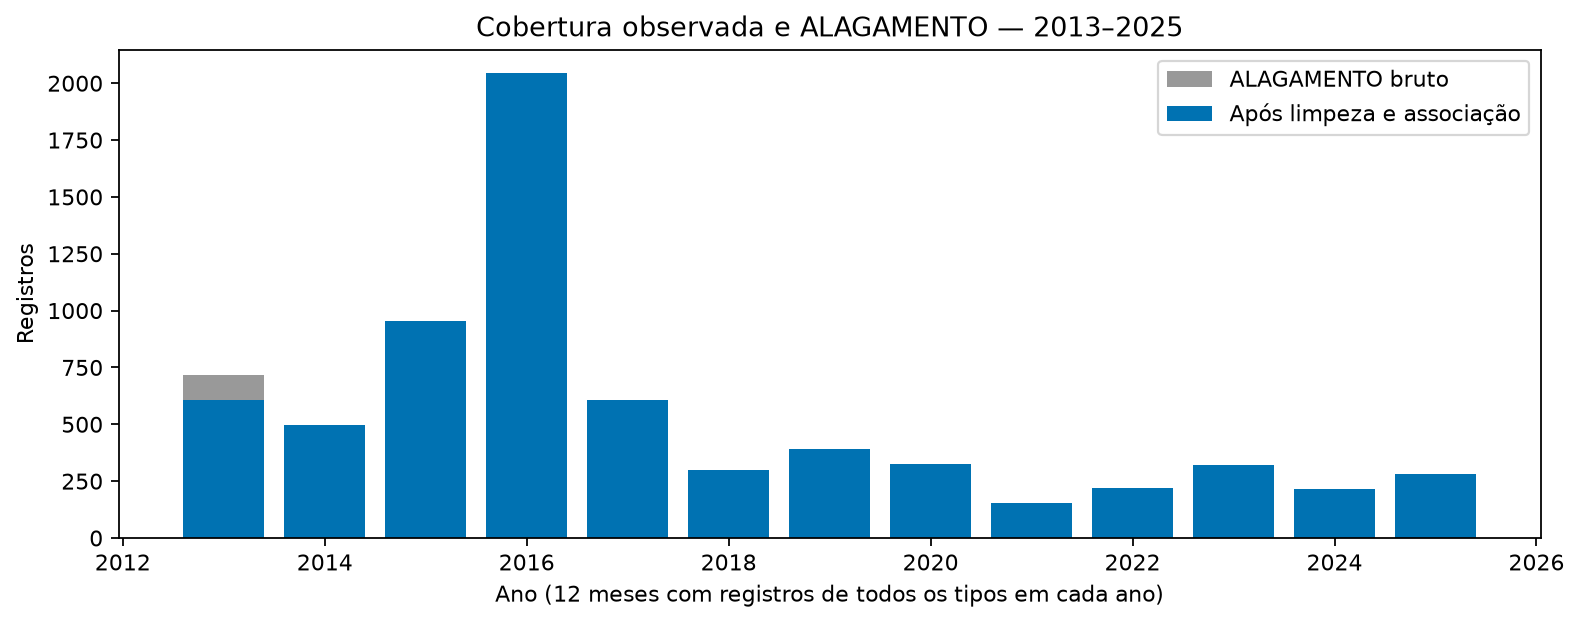

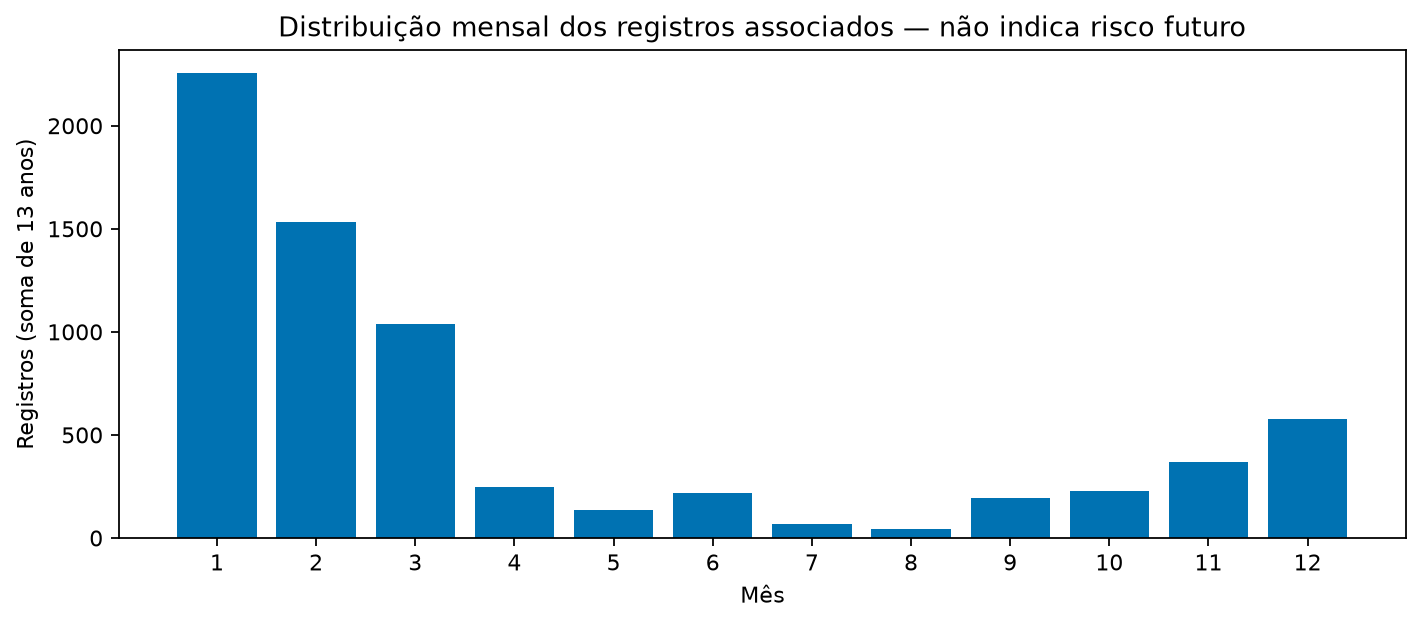

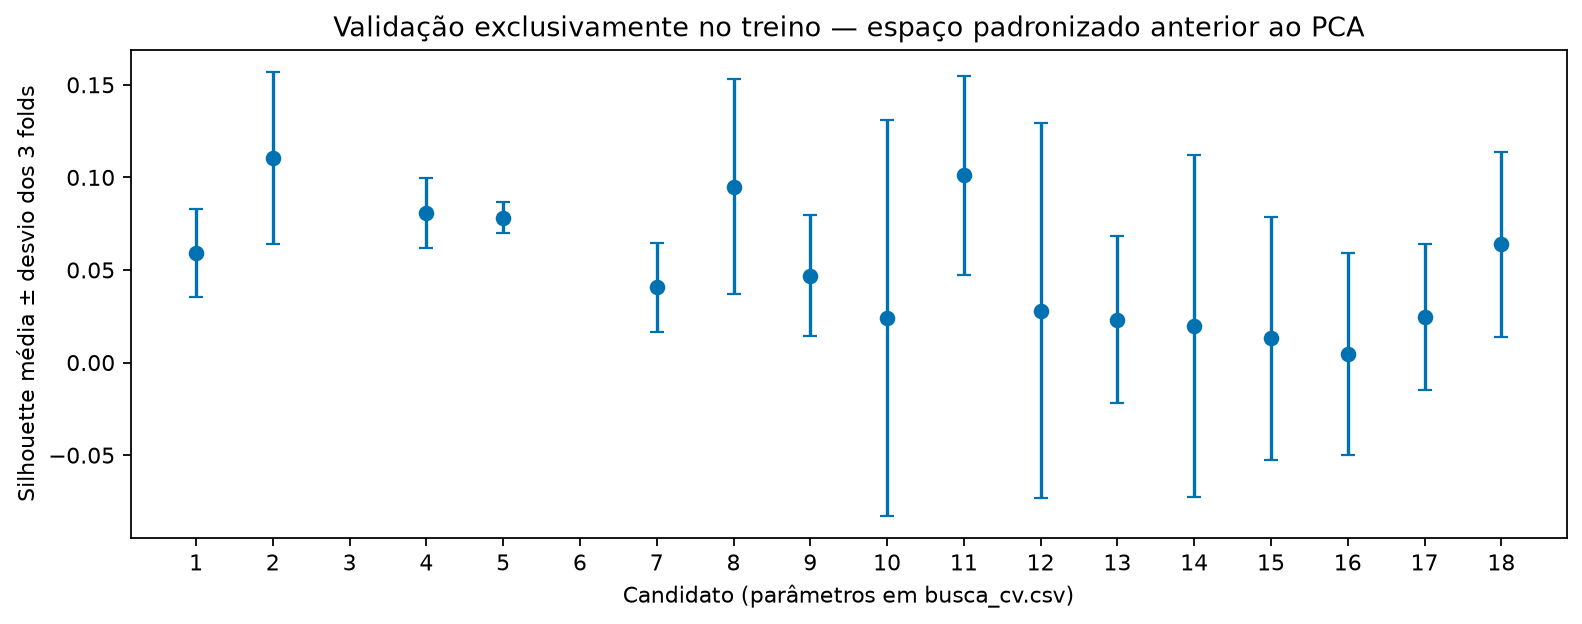

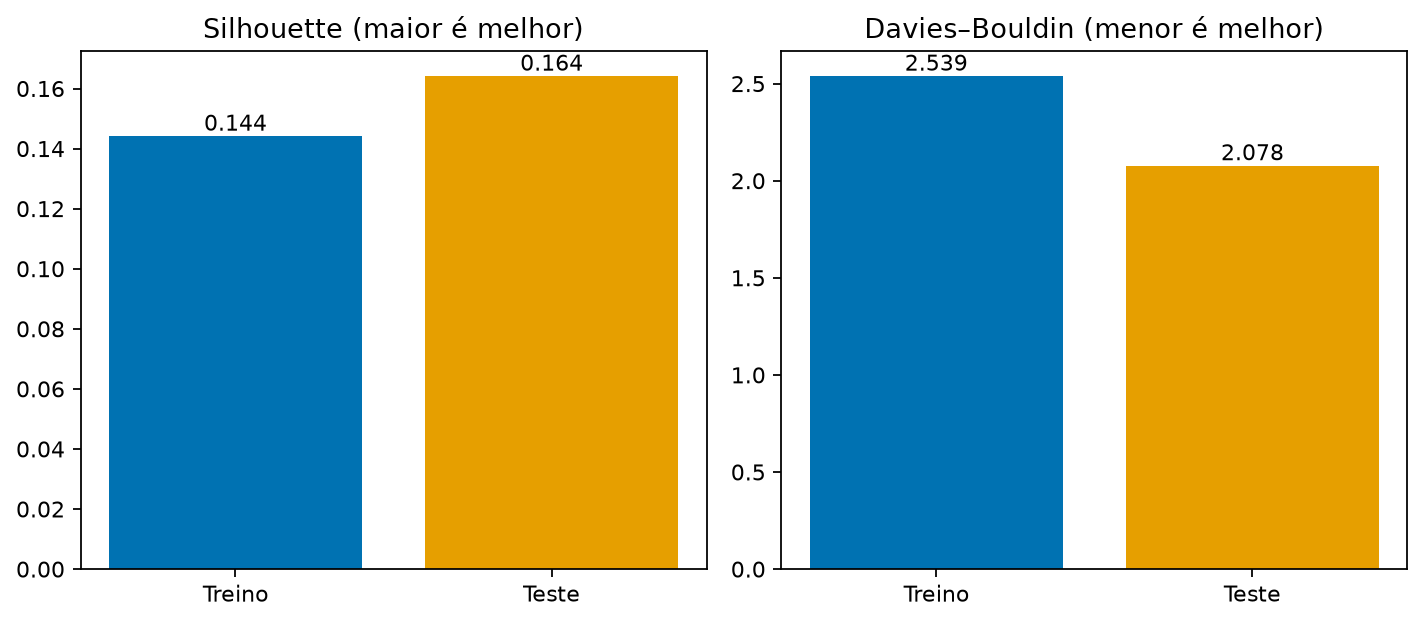

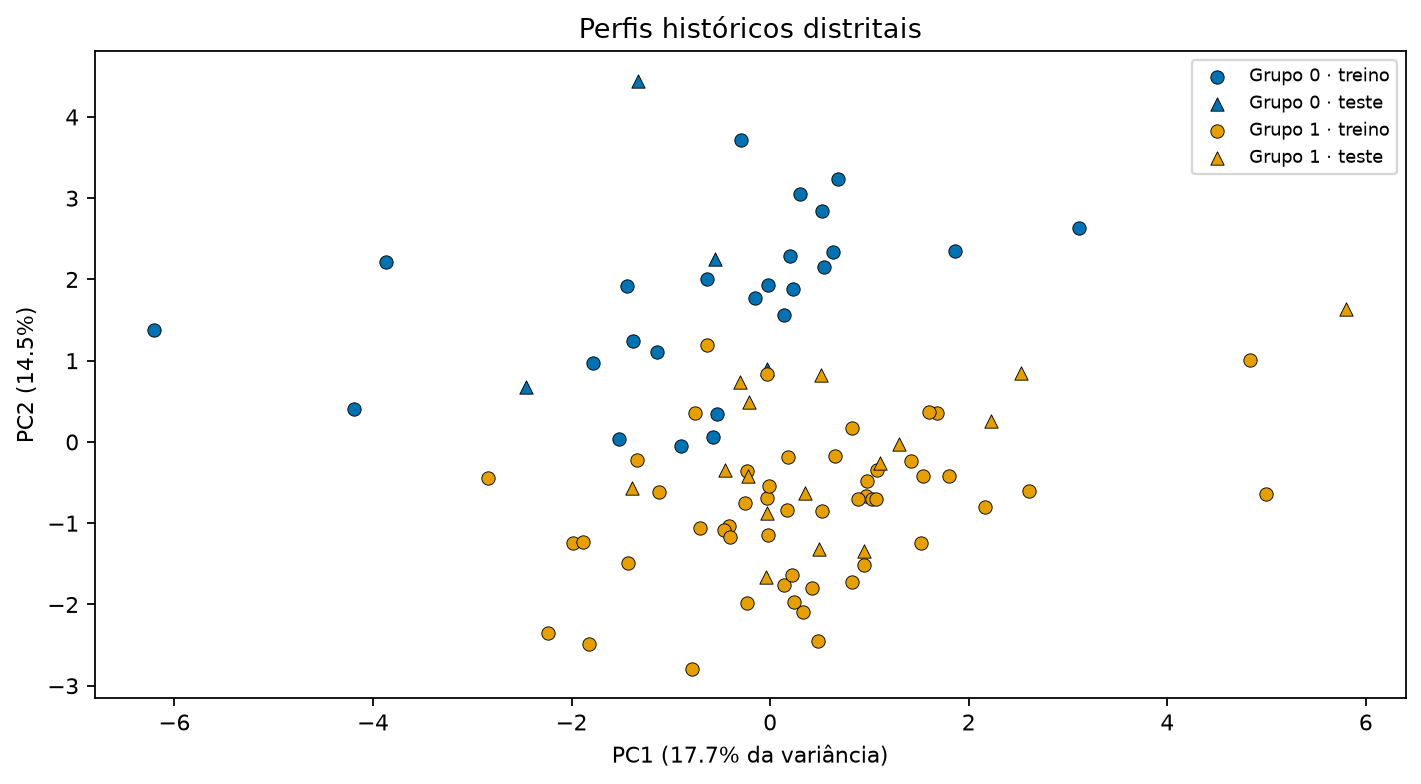

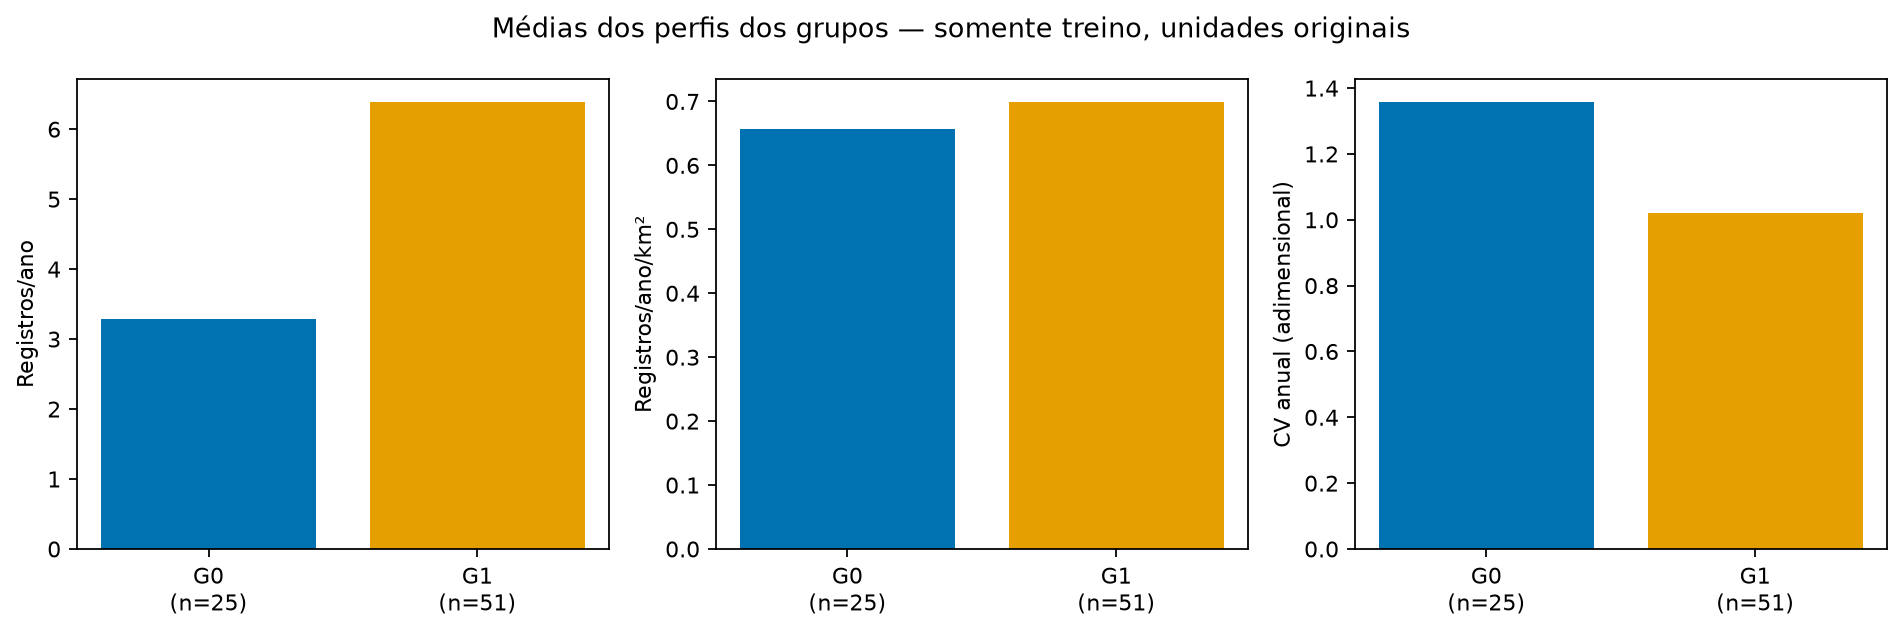

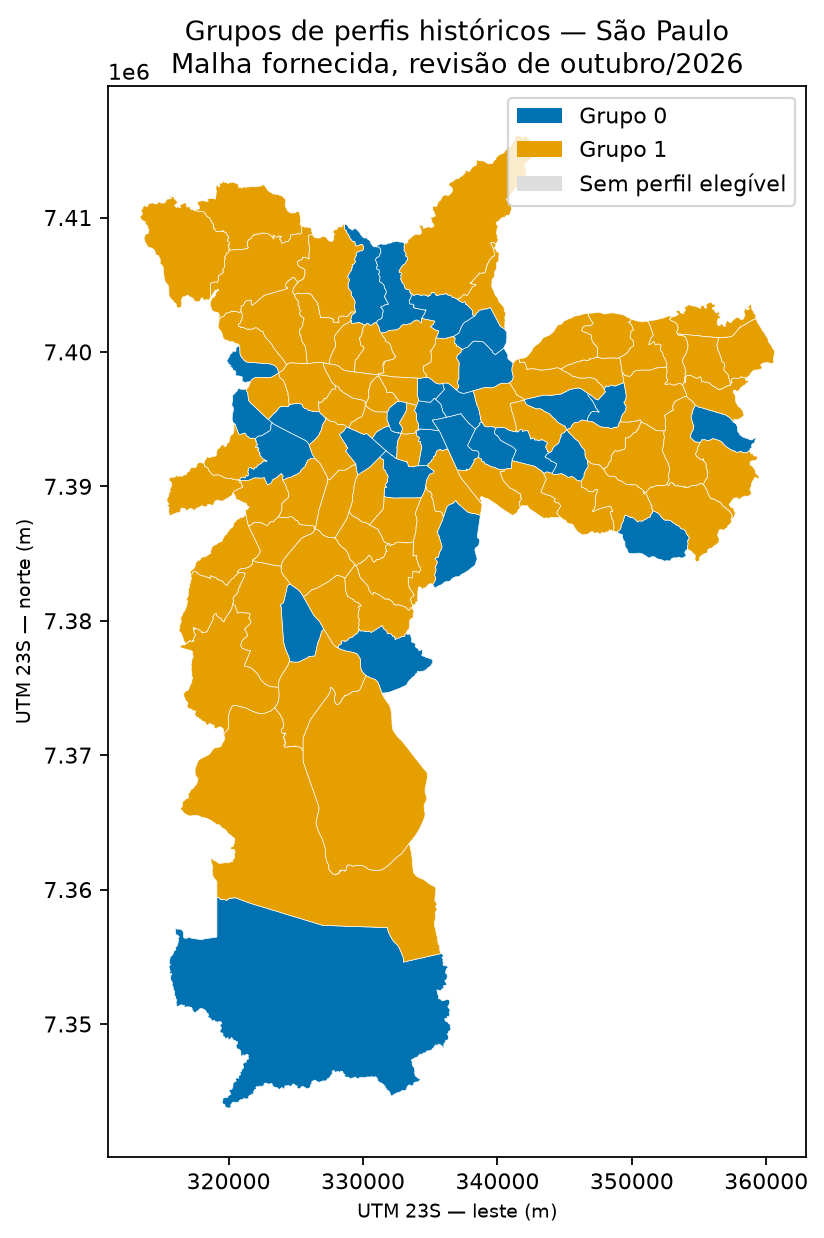

In [7]:
s = e.plots(s)
for name in sorted(e.FIG.glob('*.png')):
    display(Image(filename=str(name)))

## Leitura para o cidadão, limitações e conclusão

Métricas próximas entre treino e teste não provam ausência de overfitting. A busca pode superestimar a validação em uma amostra pequena; grupos reduzidos, outliers, volume de notificações e dependência entre vizinhos afetam os resultados. O modelo não valida risco. O histórico de notificações pode refletir mudanças administrativas e subnotificação.

Os perfis apoiam a investigação de áreas para acompanhamento. As fontes municipais consultadas relacionam o Jardim Peri ao distrito de Cachoeirinha; os links e o resultado distrital aparecem na conclusão gerada abaixo. Faltam coordenadas dos pontos candidatos e validação territorial para caracterizar as ruas específicas. A seleção de três pontos exige observação e conversas reais com moradores. O indicador de tempo de consulta da Ficha não é medido aqui. ODS 11.5 e 13.1 representam contribuição informacional e preparação, sem comprovação de redução de danos. A próxima célula gera relatório, README e roteiro com as contagens e métricas desta execução.

In [8]:
report = e.documents(s)
display(Markdown(report))

# Relatório de IA & Machine Learning — Água na Rua

Síntese de aproximadamente duas páginas (Markdown não fixa paginação). Detalhes e saídas no [notebook](ml/agua_na_rua_ml.ipynb).

## Problema, dados e preparação

Pergunta: quais distritos de São Paulo apresentam perfis semelhantes de frequência, recorrência e sazonalidade dos registros públicos de alagamento? O aplicativo tem recorte inicial no Jardim Peri; este experimento independente analisa a cidade em resolução distrital.

7032 registros brutos de ALAGAMENTO em 2013–2025; 110 duplicatas removidas; 5 sem associação distrital unívoca; **6917 registros na análise principal**, em 96 distritos.

Após a limpeza, o maior volume anual é 2045 em 2016; janeiro–março concentram 69.8% dos registros. Isso descreve esta base de notificações, sem demonstrar tendência física de alagamentos ou efeito de intervenções.

Foram auditados os 14 arquivos anuais fornecidos: 2013–2025 são independentes pelas datas observadas; 2026 cobre janeiro–setembro e foi excluído. Os quatro tipos encontrados são ALAGAMENTO, INUNDACAO, DESLIZAMENTO e QUEDA DE ARVORE. Apenas ALAGAMENTO entra na análise. As datas de todos os registros são válidas e correspondem ao ano do arquivo. Removeram-se repetições exatas com identificador conhecido, data, tipo, geometria e demais atributos iguais, ignorando o FID; registros com ID vazio foram preservados. A associação espacial usa interseção com 96 distritos, sem duplicar pontos de fronteira.

Fontes: [ocorrências GeoSampa](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/432c06b1-03a1-4b1f-9210-423e1b58e869) e [distritos GeoSampa](https://metadados.geosampa.prefeitura.sp.gov.br/geonetwork/srv/api/records/51f75eab-6d90-451e-9f80-c21c1ac72630), catálogos consultados em 12/11/2026. As cópias locais têm SHA-256 no manifesto. Data e URL direta dos downloads originais não foram fornecidas. Os catálogos registram acesso sem restrições, mas o campo genérico de licença não identifica uma licença específica de redistribuição.

## Modelo e avaliação

KMeans + PCA é permitido pelo edital e explora perfis sem rótulo verdadeiro de risco. PCA reduz correlações; KMeans resume perfis por centroides, com sensibilidade à escala e a outliers.

A unidade é o distrito administrativo. O split 80/20 usa IDs ordenados e seed 42. O teste contém outros distritos no mesmo período; não mede previsão temporal. A grade tem 18 combinações de exatamente três hiperparâmetros: número de grupos [2,3,4], reinicializações [10,30] e variância retida pelo PCA [0,80;0,90;0,95]. Mais reinicializações buscam mínimos melhores da inércia. KFold de três partes, embaralhado com seed 42, usa exclusivamente o treino. Cada fold ajusta remoção de constantes, StandardScaler, PCA full e KMeans no subtreino. A validação recebe predict, sem novo ajuste. Silhouette é calculada antes do PCA, no espaço padronizado pelo subtreino, comparável entre configurações. Só candidatos com três folds válidos concorrem; desempates: menor desvio, menor k e ordem determinística. O teste é consultado uma vez após a escolha; o pipeline salvo permanece ajustado somente no treino.

Os atributos são log1p da média anual e da densidade anual por km², fração dos 13 anos com registro, CV anual (desvio populacional/média) e 12 proporções mensais. Área vem da geometria em EPSG:31983. As proporções somam 1 e recebem padronização individual: juntas podem ter peso maior que um atributo de volume. A dependência entre volume e densidade também influencia o resultado. Essas escolhas foram fixadas antes da busca; não houve seleção usando o teste. Distritos sem registros têm sazonalidade e CV indefinidos e ficam fora do modelo, sem imputação de zeros. Identificadores, coordenadas e nomes não entram no treinamento.


Melhor configuração: `n_clusters=2`, `n_init=10`, `pca.n_components=0.9`. Silhouette de validação: **0.1106 ± 0.0464** (3 folds). Dos 18 candidatos, 16 tiveram três folds válidos; candidatos [3, 6] ficaram fora da seleção por terem um fold com somente um grupo previsto (Silhouette indefinida, registrada como N/A).

| Conjunto | n | Grupos | Silhouette | Davies_Bouldin |
| --- | --- | --- | --- | --- |
| treino | 76 | 2 | 0.1442 | 2.5393 |
| teste | 20 | 2 | 0.1642 | 2.0780 |

O PCA reteve 11 componentes, explicando 92.88% da variância do treino. Os grupos são identificadores neutros, sem ordem de perigo. Perfis médios somente do treino:

| grupo | n | media_anual | densidade_anual_km2 | fracao_anos_com_registro | cv_anual |
| --- | --- | --- | --- | --- | --- |
| 0 | 25 | 3.286 | 0.657 | 0.572 | 1.359 |
| 1 | 51 | 6.392 | 0.699 | 0.816 | 1.02 |

## Conclusões e limites

As Silhouettes observadas (treino 0.1442, validação 0.1106 e teste 0.1642) indicam separação fraca: os perfis se sobrepõem e não sustentam uma tipologia forte. O teste ligeiramente superior ao treino não comprova generalização espacial nem ausência de overfitting.

A presença de registros de todos os tipos nos 156 meses sustenta a cobertura observada, mas não comprova captura completa dos alagamentos. Zero significa zero registros na base consultada; não ausência de alagamentos. Notificação, mudanças de sistema, outliers e subnotificação podem dominar os grupos. A amostra é pequena e distritos vizinhos têm dependência espacial. Proximidade entre métricas de treino e teste não demonstra ausência de overfitting; a busca sobre uma amostra pequena também pode superestimar a validação. Grupos pequenos e dispersão dentro dos grupos devem ser considerados. Silhouette maior indica separação mais clara; Davies–Bouldin menor indica maior compactação relativa, sem medir acurácia nem probabilidade de enchente.

A malha única de outubro/2026 foi aplicada retrospectivamente e dois polígonos foram reparados em memória. Pontos fora da malha ou ambíguos não foram deslocados para o distrito mais próximo. Os campos reais são data/ocorrencia/geom; não há nm_distrito. O significado temporal adotado é a data armazenada na exportação de ocorrências, sem documentação que permita distinguir abertura, evento ou encerramento. Os identificadores name não são globalmente únicos, e há ausências em 2025.

O estudo ajuda a investigar áreas para acompanhamento; não identifica passagem segura nem prevê o próximo alagamento. Faltam coordenadas dos pontos candidatos e validação territorial para relacionar a seleção local aos perfis. A escolha dos três pontos exige observação e conversa com moradores. O indicador de tempo de consulta da Ficha não foi medido. ODS 11.5 e 13.1 são relacionados à contribuição informacional e preparação comunitária, sem evidência de redução de danos ou vítimas.


A [Prefeitura, em notícia de 04/05/2017](https://prefeitura.sp.gov.br/web/casa_verde/w/noticias/71913), situa o Jardim Peri em Vila Nova Cachoeirinha; o [quadro oficial de correspondência OD2007](https://drive.prefeitura.sp.gov.br/cidade/secretarias/upload/urbanismo/infocidade/htmls/12_correspondencia_zonas_od_e_distritos_mun_2007_258.html) relaciona a zona Jardim Peri ao distrito Cachoeirinha. Fontes consultadas em 12/11/2026, usadas como contexto territorial, sem substituir a localização dos pontos candidatos. Na malha fornecida, Cachoeirinha tem 33 registros associados no período e recebeu grupo 0 (teste). Esse agregado distrital não descreve uma rua específica.


Gráficos, métricas por fold, IDs, atribuições e modelo avaliado estão em ml/resultados/ e ml/modelos/. A equipe precisa revisar o conteúdo, gravar o vídeo e preencher os links externos.


## Verificações finais

Asserções de integridade e coerência: IDs únicos, separação sem interseção, CV restrita ao treino, 18 configurações de três hiperparâmetros, ausência de valores não finitos, balanço de limpeza e modelo preservado.

In [9]:
import numpy as np
assert s['features'].codigo_distrito.is_unique
assert not set(s['tr']) & set(s['te'])
assert len(s['search']) == 18
assert s['search'].folds_validos.eq(3).any()
assert np.isfinite(s['x'].to_numpy()).all()
assert s['assignments'].codigo_distrito.is_unique
assert int(s['features'].total_registros.sum()) == len(s['clean'])
loaded=e.joblib.load(e.MODEL/'pipeline_avaliado.joblib')
assert np.array_equal(loaded.predict(s['x']),s['assignments'].grupo)
print('Verificações concluídas. Modelo ajustado apenas no treino; saídas e documentação salvas.')

Verificações concluídas. Modelo ajustado apenas no treino; saídas e documentação salvas.
